# Logistic Regression / Ibm Hr Analytic Employee Attrition & Performance

**Type:** Guided machine-learning practice notebook (course-based study).  
**Purpose:** Explore the dataset and the modeling/preprocessing operations illustrated in the code below.  
**Data in this folder:** `Bengaluru_House_Data.csv`, `WA_Fn-UseC_-HR-Employee-Attrition.csv`.  
**Methods referenced:** `SVC`, `SVR`.

> **Reproducibility note:** Run cells sequentially from this notebook’s folder. Outputs are historical study results, not independently validated benchmarks. The data files were supplied with the original archive; see `DATA_SOURCES.md` at the repository root for provenance checks.


In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("Bengaluru_House_Data.csv")

In [3]:
df

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00
...,...,...,...,...,...,...,...,...,...
13315,Built-up Area,Ready To Move,Whitefield,5 Bedroom,ArsiaEx,3453,4.0,0.0,231.00
13316,Super built-up Area,Ready To Move,Richards Town,4 BHK,NaN,3600,5.0,NaN,400.00
13317,Built-up Area,Ready To Move,Raja Rajeshwari Nagar,2 BHK,Mahla T,1141,2.0,1.0,60.00
13318,Super built-up Area,18-Jun,Padmanabhanagar,4 BHK,SollyCl,4689,4.0,1.0,488.00


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     13320 non-null  object 
 1   availability  13320 non-null  object 
 2   location      13319 non-null  object 
 3   size          13304 non-null  object 
 4   society       7818 non-null   object 
 5   total_sqft    13320 non-null  object 
 6   bath          13247 non-null  float64
 7   balcony       12711 non-null  float64
 8   price         13320 non-null  float64
dtypes: float64(3), object(6)
memory usage: 936.7+ KB


In [5]:
df.isna().sum()

area_type          0
availability       0
location           1
size              16
society         5502
total_sqft         0
bath              73
balcony          609
price              0
dtype: int64

In [6]:
df = df.dropna(subset=['size'])

In [7]:
df["bhk"] = df["size"].str.split().str[0].astype(float)
df = df.drop("size", axis = 1)

C:\Users\emres\AppData\Local\Temp\ipykernel_27368\338406279.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["bhk"] = df["size"].str.split().str[0].astype(float)


In [8]:
df["bhk"].value_counts()

bhk
2.0     5528
3.0     4857
4.0     1417
1.0      656
5.0      356
6.0      221
7.0      100
8.0       89
9.0       54
10.0      14
11.0       4
27.0       1
19.0       1
16.0       1
43.0       1
14.0       1
12.0       1
13.0       1
18.0       1
Name: count, dtype: int64

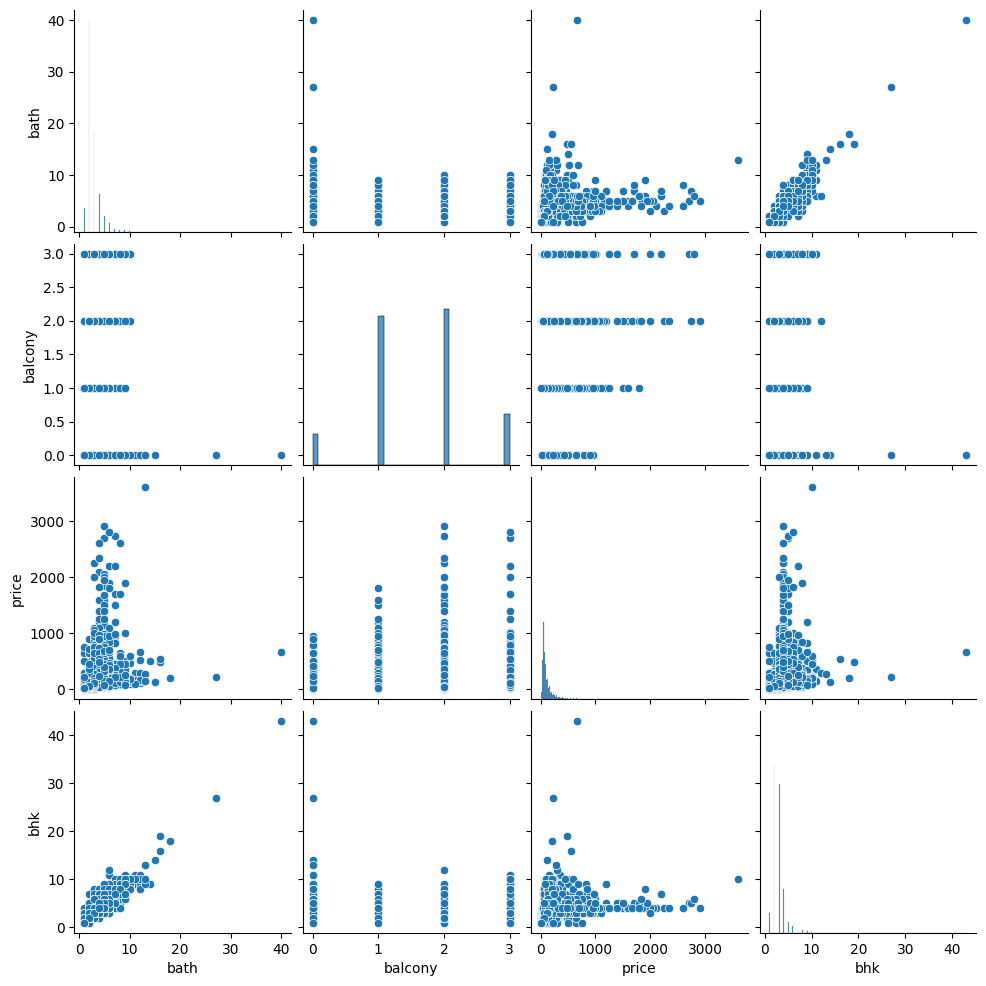

In [9]:
sns.pairplot(df)
plt.show()

In [10]:
df[df["bhk"] > 20]

,area_type,availability,location,society,total_sqft,bath,balcony,price,bhk
1718,Super built-up Area,Ready To Move,2Electronic City Phase II,NaN,8000,27.0,0.0,230.0,27.0
4684,Plot Area,Ready To Move,Munnekollal,NaN,2400,40.0,0.0,660.0,43.0


In [11]:
def convert_sqft_to_num(x):
    tokens = str(x).split('-')
    if len(tokens) == 2:
        return (float(tokens[0]) + float(tokens[1])) / 2
    try:
        return float(x)
    except:
        return None

df['total_sqft'] = df['total_sqft'].apply(convert_sqft_to_num)

df = df.dropna()

In [12]:
df["sqft_per_bhk"] = df["total_sqft"] / df["bhk"]

In [13]:
df = df[df["sqft_per_bhk"] >= 300]

In [14]:
df = df.drop("sqft_per_bhk", axis = 1)

In [15]:
print(df.shape)

(7439, 9)


In [16]:
from sklearn.preprocessing import LabelEncoder

In [17]:
df = df[["total_sqft", "bath", "bhk", "price"]]

In [18]:
df["fiyat_kategorisi"] = pd.qcut(df["price"], q = 3, labels = ["ucuz", "orta", "luks"])

In [19]:
le = LabelEncoder()

In [20]:
df["hedef_sinif"] = le.fit_transform(df["fiyat_kategorisi"])

In [21]:
df.head()

,total_sqft,bath,bhk,price,fiyat_kategorisi,hedef_sinif
0,1056.0,2.0,2.0,39.07,ucuz,2
1,2600.0,5.0,4.0,120.00,luks,0
3,1521.0,3.0,3.0,95.00,luks,0
5,1170.0,2.0,2.0,38.00,ucuz,2
11,2785.0,5.0,4.0,295.00,luks,0


In [22]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import classification_report
import time

In [23]:
X = df.drop(["price", "fiyat_kategorisi", "hedef_sinif"], axis = 1)
y = df["hedef_sinif"]

In [24]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

In [25]:
scaler = StandardScaler()

In [26]:
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [27]:
basla = time.time()
svc_linear = SVC(kernel='linear')
svc_linear.fit(X_train_scaled, y_train)
print(f"Linear Süresi: {time.time() - basla:.2f} saniye")
print(classification_report(y_test, svc_linear.predict(X_test_scaled)))

Linear Süresi: 0.45 saniye
              precision    recall  f1-score   support

           0       0.81      0.80      0.80       495
           1       0.57      0.57      0.57       503
           2       0.69      0.71      0.70       490

    accuracy                           0.69      1488
   macro avg       0.69      0.69      0.69      1488
weighted avg       0.69      0.69      0.69      1488



In [28]:
basla = time.time()
svc_rbf = SVC(kernel='rbf')
svc_rbf.fit(X_train_scaled, y_train)
print(f"RBF Süresi: {time.time() - basla:.2f} saniye")
print(classification_report(y_test, svc_rbf.predict(X_test_scaled)))

RBF Süresi: 0.37 saniye
              precision    recall  f1-score   support

           0       0.84      0.78      0.81       495
           1       0.57      0.63      0.60       503
           2       0.72      0.69      0.71       490

    accuracy                           0.70      1488
   macro avg       0.71      0.70      0.70      1488
weighted avg       0.71      0.70      0.70      1488



In [29]:
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, r2_score

In [30]:
basla = time.time()
svr_model = SVR(kernel='rbf')
svr_model.fit(X_train_scaled, y_train)
print(f"Eğitim Süresi: {time.time() - basla:.2f} saniye")
y_pred = svr_model.predict(X_test_scaled)
print(f"R² Skoru (Başarı Oranı): {r2_score(y_test, y_pred):.2f}")
print(f"Ortalama Mutlak Hata (MAE): {mean_absolute_error(y_test, y_pred):.2f} Birim")

Eğitim Süresi: 0.52 saniye
R² Skoru (Başarı Oranı): 0.61
Ortalama Mutlak Hata (MAE): 0.37 Birim


In [31]:
from sklearn.model_selection import GridSearchCV

In [32]:
param_grid = {
    'C': [10, 100, 1000, 10000],          
    'gamma': ['scale', 0.1, 0.01, "auto", 1], 
    'epsilon': [0.1, 1, 5, 25]         
}

In [33]:
basla = time.time()
grid_search = GridSearchCV(SVR(kernel='rbf'), param_grid, cv=3, scoring='r2', n_jobs = -1, verbose=2)
grid_search.fit(X_train_scaled, y_train)
print(f"\nOptimizasyon Süresi: {time.time() - basla:.2f} saniye")

Fitting 3 folds for each of 80 candidates, totalling 240 fits

Optimizasyon Süresi: 55.91 saniye


In [34]:
grid_search.best_params_

{'C': 100, 'epsilon': 0.1, 'gamma': 'auto'}

In [35]:
best_svr = grid_search.best_estimator_
y_pred_tuned = best_svr.predict(X_test_scaled)

In [36]:
print(f"YENİ R² Skoru: {r2_score(y_test, y_pred_tuned):.2f}")
print(f"YENİ Ortalama Mutlak Hata (MAE): {mean_absolute_error(y_test, y_pred_tuned):.2f} Birim")

YENİ R² Skoru: 0.62
YENİ Ortalama Mutlak Hata (MAE): 0.36 Birim
